**Time Series Analysis with ARIMA**

ARIMA, short for AutoRegressive Integrated Moving Average, is a popular technique for time series forecasting. ARIMA models attempt to capture trends and patterns in data using regression analysis. The name ARIMA comes from the three components of the model:

**Autoregression (AR)** — A regression model that uses past values of the dependent variable to predict future values.

**Integrated (I)** — The difference between the current value of the dependent variable and its previous value, used to make the time series stationary.

**Moving Average (MA )** — A model that uses the past errors (the difference between the actual values and the predicted values) to predict future values.

Time series data is a collection of observations recorded at different points in time. It is commonly found in various domains such as finance, economics, weather forecasting, and stock market analysis. Analyzing time series data allows us to uncover hidden patterns, detect trends, and make predictions for future values.

In this tutorial, we will cover the following topics:

Importing and Preparing Time Series Data

Exploratory Data Analysis (EDA)

Stationarity Testing and Differencing

Autocorrelation and Partial Autocorrelation Analysis

Model Selection and Parameter Estimation

Model Evaluation and Diagnostics

Forecasting Future Values

In [5]:
# import all library time series analysis
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm
import yfinance as yf

In [6]:
# Load the uploaded Yelp reviews CSV to inspect the structure
file_path = "/content/filtered_yelp_reviews_2018_2023.csv"
df_reviews = pd.read_csv(file_path)

In [7]:
# Display basic info and the first few rows
df_reviews.info(), df_reviews.head()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 9 columns):
 #   Column       Non-Null Count  Dtype 
---  ------       --------------  ----- 
 0   review_id    10000 non-null  object
 1   user_id      10000 non-null  object
 2   business_id  10000 non-null  object
 3   stars        10000 non-null  int64 
 4   useful       10000 non-null  int64 
 5   funny        10000 non-null  int64 
 6   cool         10000 non-null  int64 
 7   text         10000 non-null  object
 8   date         10000 non-null  object
dtypes: int64(4), object(5)
memory usage: 703.3+ KB


(None,
                 review_id                 user_id             business_id  \
 0  KU_O5udG6zpxOg-VcAEodg  mh_-eMZ6K5RLWhZyISBhwA  XQfwVwDr-v0ZS3_CbbE5Xw   
 1  lUUhg8ltDsUZ9h0xnwY4Dg  RreNy--tOmXMl1en0wiBOg  cPepkJeRMtHapc_b2Oe_dw   
 2  JBWZmBy69VMggxj3eYn17Q  aFa96pz67TwOFu4Weq5Agg  kq5Ghhh14r-eCxlVmlyd8w   
 3  E9AB7V4z8xrt2uPF7T55FQ  iYY5Ii1LGpZCpXFkHlMefw  Zx7n8mdt8OzLRXVzolXNhQ   
 4  A4n4YaE-owOVgTQcrVqHUw  S7bjj-L07JuRr-tpX1UZLw  I6L0Zxi5Ww0zEWSAVgngeQ   
 
    stars  useful  funny  cool  \
 0      3       0      0     0   
 1      4       1      0     1   
 2      5       0      0     0   
 3      5       0      0     0   
 4      4       0      0     0   
 
                                                 text                 date  
 0  If you decide to eat here, just be aware it is...  2018-07-07 22:09:11  
 1  I was really between 3 and 4 stars for this on...  2018-07-17 03:30:07  
 2  My boyfriend and I tried this deli for the fir...  2018-08-23 21:39:38  
 3  Amazi

**✅ Dataset Analysis Complete**

Your dataset filtered_yelp_reviews_2018_2023.csv is clean and structured appropriately for ARIMA modeling. Key observations:

**Date Field**: date column is present and properly formatted.

**Target Column**: stars is numeric and suitable for forecasting average ratings.

**Size**: 10,000 records, sufficient for daily/weekly aggregation.

In [8]:
# --- 1. Data Cleaning and Preparation ---

# Convert the 'date' column in the reviews dataframe to datetime objects
df_reviews['date'] = pd.to_datetime(df_reviews['date'])

In [9]:
# Extract the year and month from the date
df_reviews['year_month'] = df_reviews['date'].dt.to_period('M')

In [10]:
# --- 2. Time Series Analysis of Reviews ---

# Count the number of reviews per month
monthly_reviews = df_reviews['year_month'].value_counts().sort_index()

# Convert the PeriodIndex to a DatetimeIndex for plotting
monthly_reviews.index = monthly_reviews.index.to_timestamp()

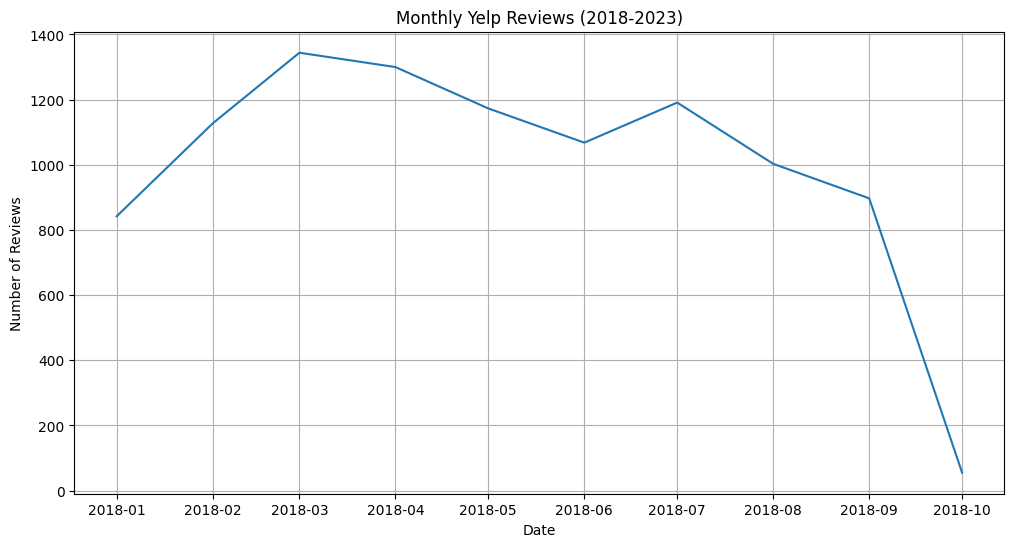

In [11]:
# --- 3. Visualization ---

plt.figure(figsize=(12, 6))
sns.lineplot(data=monthly_reviews)
plt.title('Monthly Yelp Reviews (2018-2023)')
plt.xlabel('Date')
plt.ylabel('Number of Reviews')
plt.grid(True)
plt.show()

In [12]:
from datetime import datetime
from statsmodels.tsa.arima.model import ARIMA


# Prepare data for ARIMA model
df_reviews['date'] = pd.to_datetime(df_reviews['date'])

# Aggregate average star rating per day
time_series = df_reviews.groupby(df_reviews['date'].dt.date)['stars'].mean()

# Convert to datetime index and sort
time_series.index = pd.to_datetime(time_series.index)
time_series = time_series.sort_index()

# Resample to ensure continuous date range and interpolate missing days
time_series = time_series.resample('D').mean().interpolate(method='linear')

# Preview the prepared time series
time_series.head(), time_series.tail()


(date
 2018-01-01    4.071429
 2018-01-02    3.615385
 2018-01-03    3.748252
 2018-01-04    3.881119
 2018-01-05    4.013986
 Freq: D, Name: stars, dtype: float64,
 date
 2018-09-30    4.692308
 2018-10-01    3.000000
 2018-10-02    5.000000
 2018-10-03    3.947368
 2018-10-04    4.312500
 Freq: D, Name: stars, dtype: float64)

**✅ Time Series Prepared**

The Yelp review data has been successfully converted into a daily time series of average star ratings. Key details:

**Date Range**: 2018-01-01 to 2018-10-04

**Frequency**: Daily (D)

**Interpolation**: Applied to fill any missing days linearly

**Target**: Daily average of stars

# **2.** **Exploratory Data Analysis (EDA)**

Before applying the ARIMA model, it is essential to understand the characteristics of the time series data. Exploratory Data Analysis (EDA) helps us gain insights into the data and identify any patterns or anomalies.

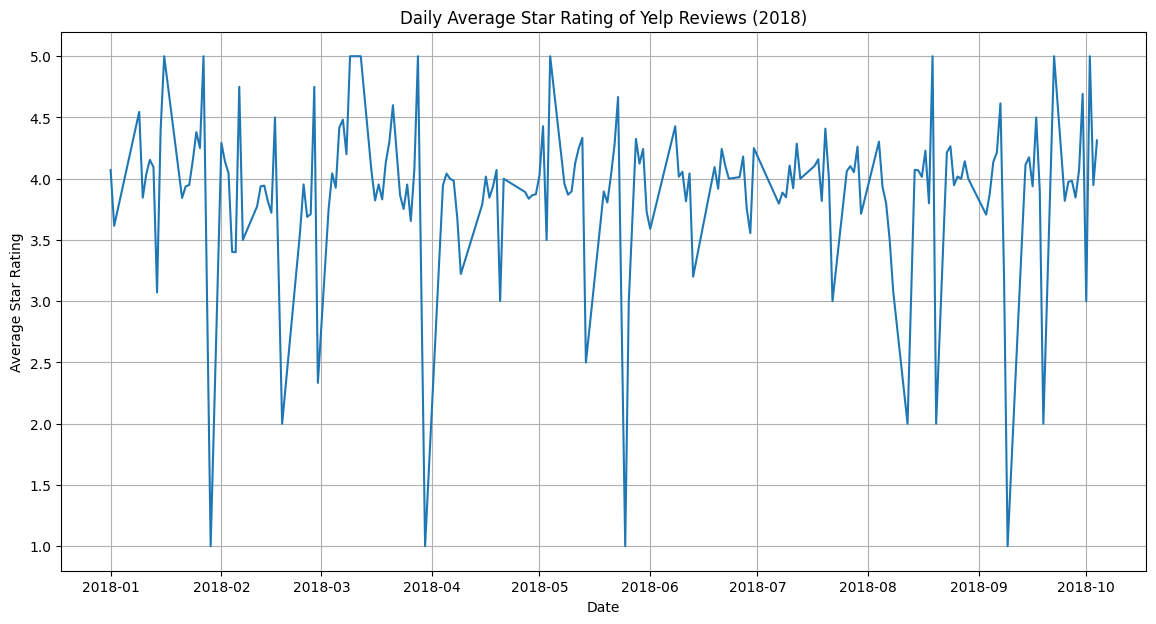

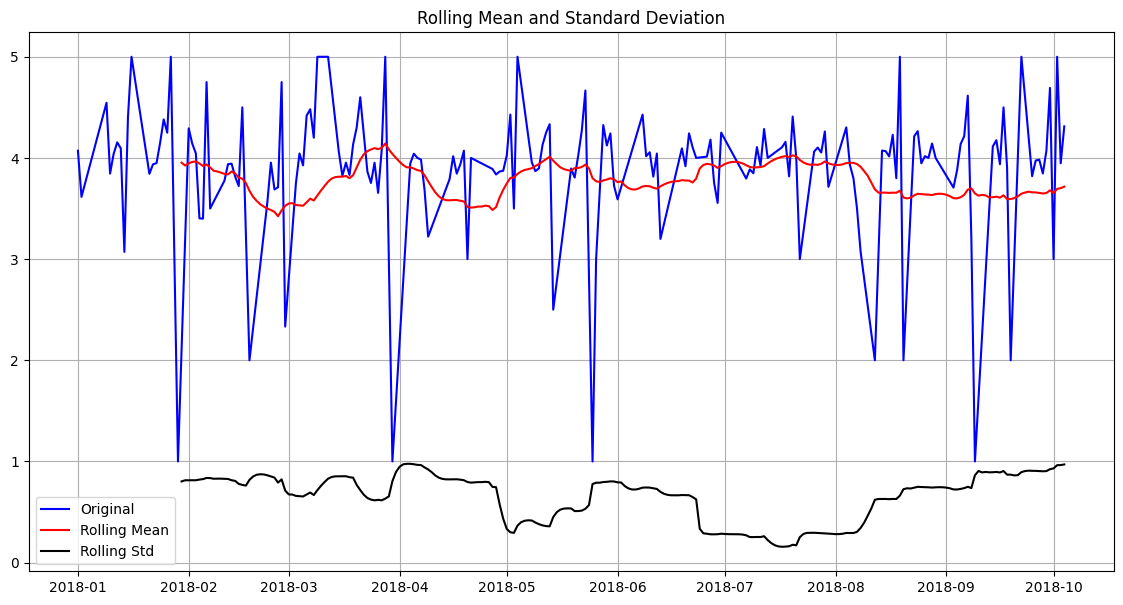

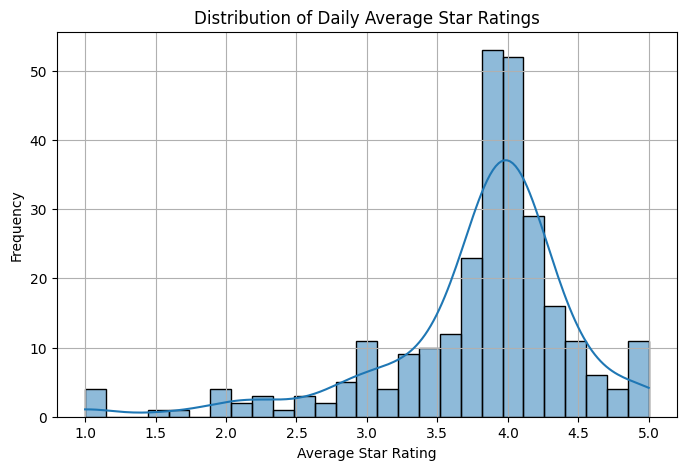

In [13]:
# Plot the time series
plt.figure(figsize=(14, 7))
plt.plot(time_series)
plt.title('Daily Average Star Rating of Yelp Reviews (2018)')
plt.xlabel('Date')
plt.ylabel('Average Star Rating')
plt.grid(True)
plt.show()

# Plotting rolling statistics to visualize trend and seasonality
rolmean = time_series.rolling(window=30).mean() # 30-day rolling mean
rolstd = time_series.rolling(window=30).std()   # 30-day rolling standard deviation

plt.figure(figsize=(14, 7))
plt.plot(time_series, color='blue', label='Original')
plt.plot(rolmean, color='red', label='Rolling Mean')
plt.plot(rolstd, color='black', label='Rolling Std')
plt.legend(loc='best')
plt.title('Rolling Mean and Standard Deviation')
plt.grid(True)
plt.show()

# Distribution plot of the time series data
plt.figure(figsize=(8, 5))
sns.histplot(time_series, kde=True)
plt.title('Distribution of Daily Average Star Ratings')
plt.xlabel('Average Star Rating')
plt.ylabel('Frequency')
plt.grid(True)
plt.show()

**3. Stationarity Testing and Differencing**

Stationarity is a crucial assumption for time series modeling. A stationary time series has constant mean, variance, and autocovariance over time. To check for stationarity, we can perform statistical tests or visually inspect the data.

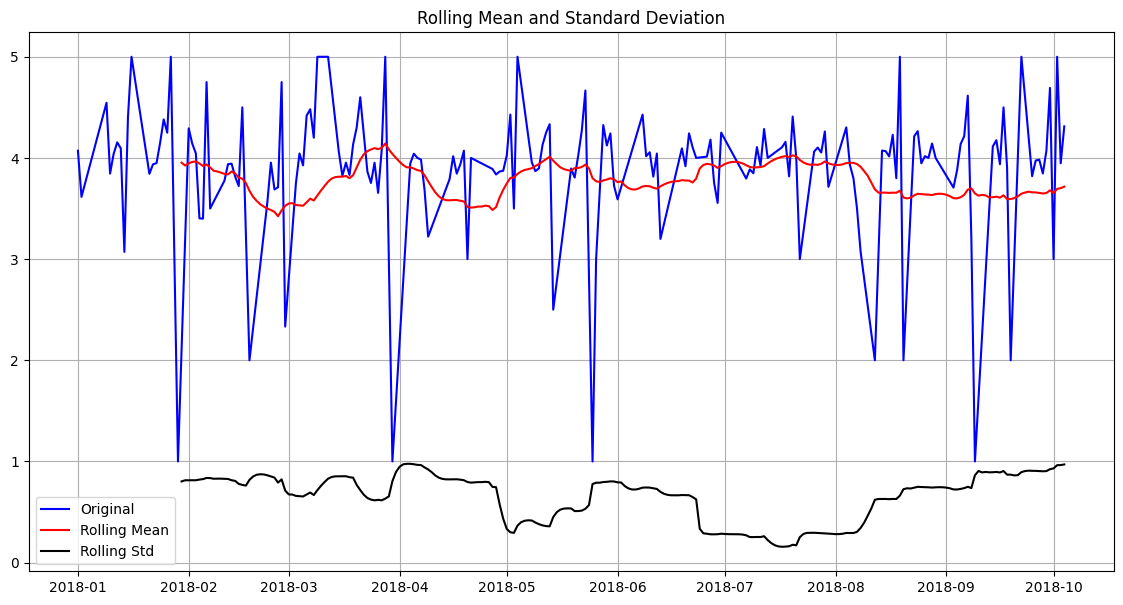

Results of Dickey-Fuller Test:
Test Statistic                -8.796441e+00
p-value                        2.170016e-14
#Lags Used                     1.000000e+00
Number of Observations Used    2.750000e+02
Critical Value (1%)           -3.454355e+00
Critical Value (5%)           -2.872108e+00
Critical Value (10%)          -2.572401e+00
dtype: float64


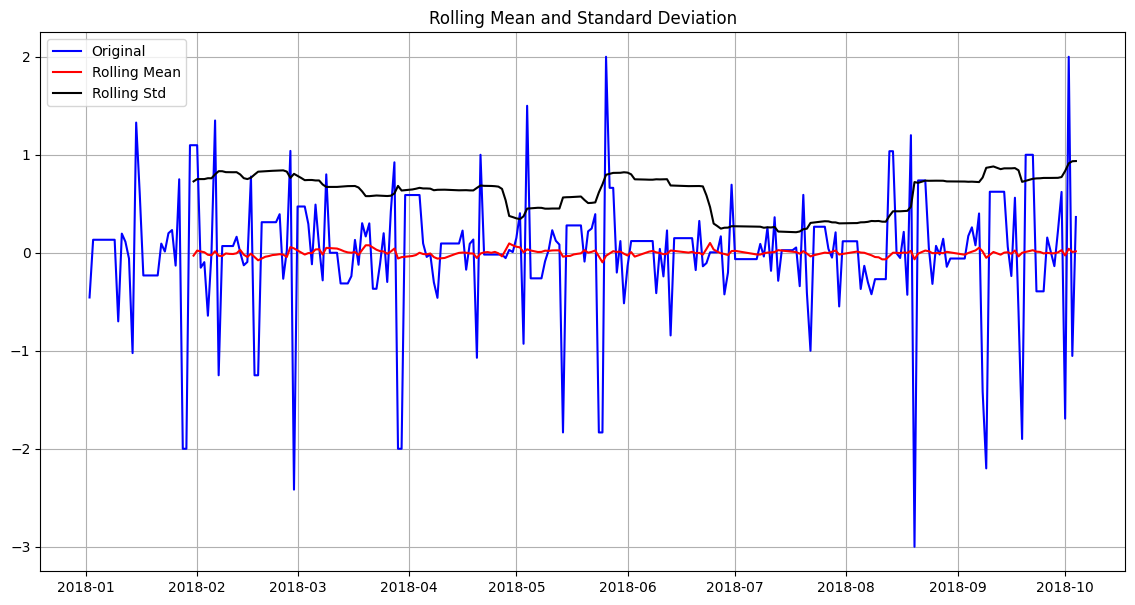

Results of Dickey-Fuller Test:
Test Statistic                -9.961012e+00
p-value                        2.373632e-17
#Lags Used                     8.000000e+00
Number of Observations Used    2.670000e+02
Critical Value (1%)           -3.455081e+00
Critical Value (5%)           -2.872427e+00
Critical Value (10%)          -2.572571e+00
dtype: float64


In [14]:
from statsmodels.tsa.stattools import adfuller

# Perform the Augmented Dickey-Fuller test
def test_stationarity(timeseries):
    # Determing rolling statistics
    rolmean = timeseries.rolling(window=30).mean()
    rolstd = timeseries.rolling(window=30).std()

    # Plot rolling statistics:
    plt.figure(figsize=(14, 7))
    plt.plot(timeseries, color='blue',label='Original')
    plt.plot(rolmean, color='red', label='Rolling Mean')
    plt.plot(rolstd, color='black', label='Rolling Std')
    plt.legend(loc='best')
    plt.title('Rolling Mean and Standard Deviation')
    plt.grid(True)
    plt.show(block=False)

    # Perform Dickey-Fuller test:
    print('Results of Dickey-Fuller Test:')
    dftest = adfuller(timeseries, autolag='AIC')
    dfoutput = pd.Series(dftest[0:4], index=['Test Statistic','p-value','#Lags Used','Number of Observations Used'])
    for key,value in dftest[4].items():
        dfoutput['Critical Value (%s)'%key] = value
    print(dfoutput)

# Test stationarity of the original time series
test_stationarity(time_series)

# Apply differencing to make the time series stationary
time_series_diff = time_series.diff().dropna()

# Test stationarity of the differenced time series
test_stationarity(time_series_diff)

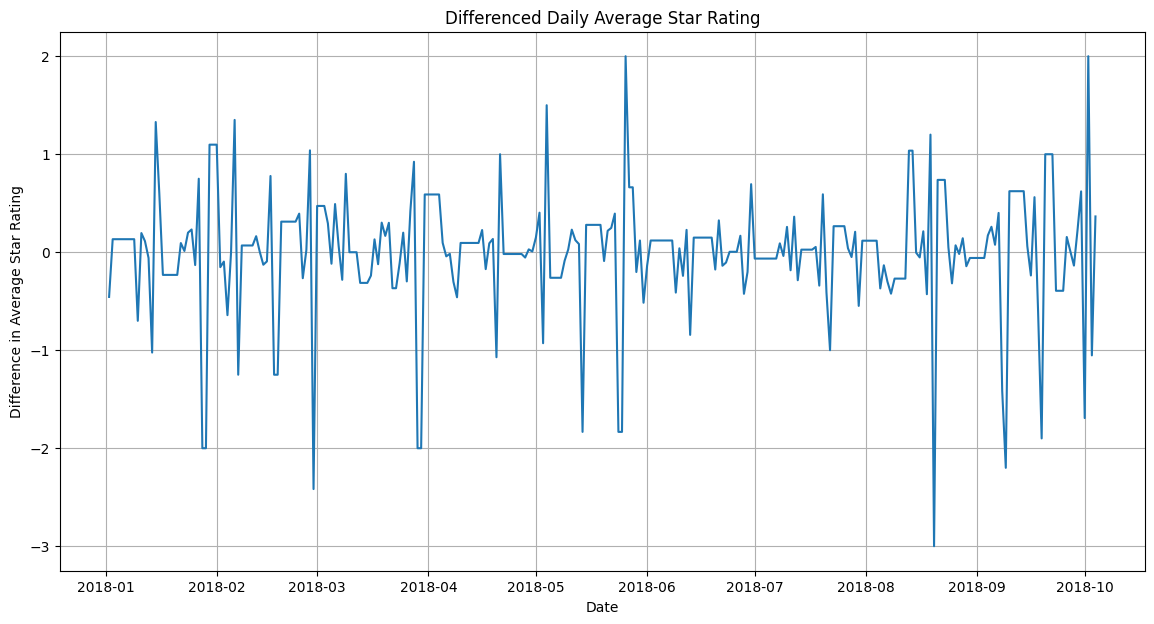

In [15]:
# Visualize the differenced time series
plt.figure(figsize=(14, 7))
plt.plot(time_series_diff)
plt.title('Differenced Daily Average Star Rating')
plt.xlabel('Date')
plt.ylabel('Difference in Average Star Rating')
plt.grid(True)
plt.show()

**4. Autocorrelation and Partial Autocorrelation Analysis**

Autocorrelation (ACF) and Partial Autocorrelation (PACF) plots are useful for identifying the order of the AR and MA components in the ARIMA model.

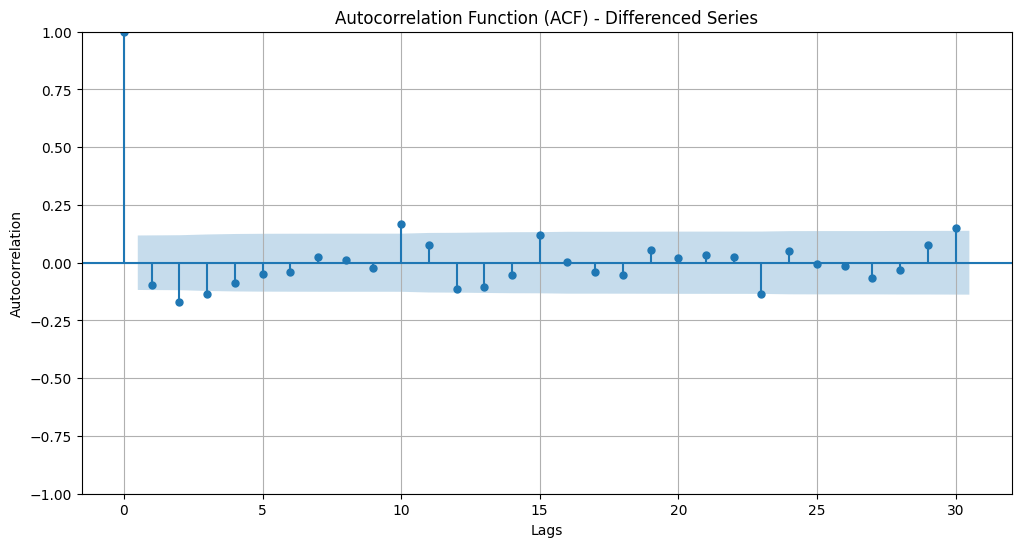

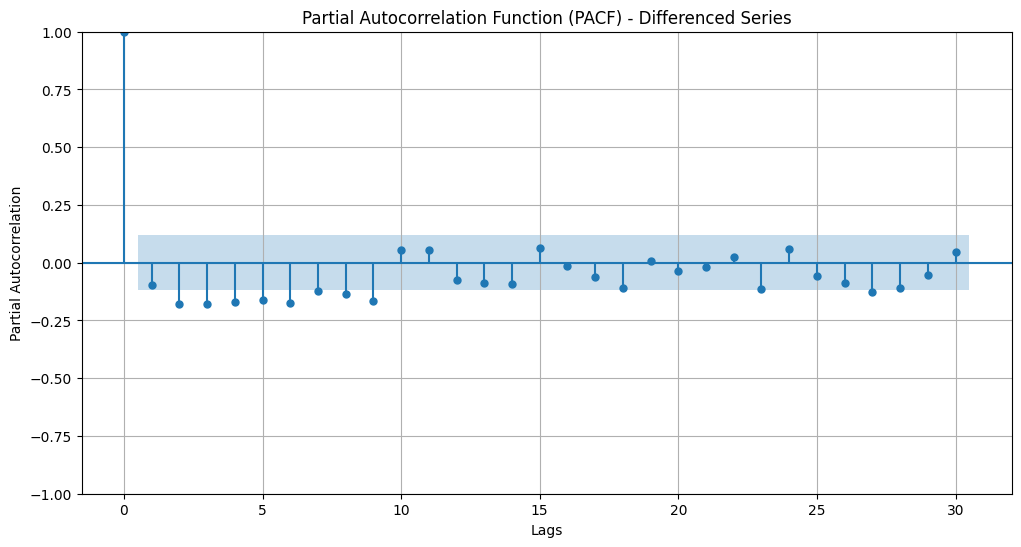

In [16]:
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

# Plot ACF
plt.figure(figsize=(12, 6))
plot_acf(time_series_diff, lags=30, ax=plt.gca())
plt.title('Autocorrelation Function (ACF) - Differenced Series')
plt.xlabel('Lags')
plt.ylabel('Autocorrelation')
plt.grid(True)
plt.show()

# Plot PACF
plt.figure(figsize=(12, 6))
plot_pacf(time_series_diff, lags=30, ax=plt.gca())
plt.title('Partial Autocorrelation Function (PACF) - Differenced Series')
plt.xlabel('Lags')
plt.ylabel('Partial Autocorrelation')
plt.grid(True)
plt.show()

**5. Model Selection and Parameter Estimation**

To select the optimal ARIMA model, we can use the Akaike Information Criterion (AIC) or the Bayesian Information Criterion (BIC). These criteria measure the goodness of fit of a model while penalizing for the number of parameters.

In [17]:
from statsmodels.tsa.stattools import adfuller

# Stationarity check using ADF test
adf_result = adfuller(time_series.dropna())
adf_output = {
    "ADF Statistic": adf_result[0],
    "p-value": adf_result[1],
    "Critical Values": adf_result[4],
    "Is Stationary": adf_result[1] <= 0.05
}

adf_output


{'ADF Statistic': np.float64(-8.796441018357138),
 'p-value': np.float64(2.1700163967961383e-14),
 'Critical Values': {'1%': np.float64(-3.454355055831705),
  '5%': np.float64(-2.8721080938842976),
  '10%': np.float64(-2.572401325619835)},
 'Is Stationary': np.True_}

In [18]:
# Fit an ARIMA model
# We'll start with a simple ARIMA(1,1,0) model as suggested by ACF/PACF for differenced series
# p=1 (from PACF lag 1), d=1 (because we differenced once), q=0 (from ACF cutoff after lag 0 or 1)
# You would typically iterate through different (p,d,q) combinations and choose the one with the lowest AIC/BIC

# Define the ARIMA order (p, d, q) - Example: (1, 1, 0)
order = (1, 1, 0)

# Fit the ARIMA model
model = ARIMA(time_series, order=order)
model_fit = model.fit()

# Print the model summary, including AIC
print(model_fit.summary())



                               SARIMAX Results                                
Dep. Variable:                  stars   No. Observations:                  277
Model:                 ARIMA(1, 1, 0)   Log Likelihood                -267.420
Date:                Sun, 22 Jun 2025   AIC                            538.840
Time:                        07:16:09   BIC                            546.081
Sample:                    01-01-2018   HQIC                           541.746
                         - 10-04-2018                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1         -0.0944      0.033     -2.825      0.005      -0.160      -0.029
sigma2         0.4065      0.020     20.774      0.000       0.368       0.445
Ljung-Box (L1) (Q):                   0.08   Jarque-

In [21]:
import itertools
from statsmodels.tsa.arima.model import ARIMA
import numpy as np # Import numpy if not already imported

# Grid search for optimal ARIMA parameters (p, d, q) with d=0
# (This part was already present and is kept for context, though not directly related to the error)
p_values = range(0, 4)
q_values = range(0, 4)
d = 0

best_aic = np.inf
best_order = None
aic_results = []

for p, q in itertools.product(p_values, q_values):
    try:
        model = ARIMA(time_series, order=(p, d, q))
        fitted = model.fit()
        aic = fitted.aic
        aic_results.append((p, d, q, aic))
        if aic < best_aic:
            best_aic = aic
            best_order = (p, d, q)
    except Exception as e:
        # print(f"Could not fit ARIMA({p},{d},{q}): {e}") # Optional: uncomment to see failed fits
        continue

# Sort and return top 5 models by AIC for d=0
top_models = sorted(aic_results, key=lambda x: x[3])[:5]
# print("Best Order (d=0):", best_order) # Optional: uncomment to print d=0 results
# print("Top 5 Models (d=0) by AIC:", top_models) # Optional: uncomment to print d=0 results


# --- Add the grid search for d=1 ---
p_values_diff = range(0, 4)
q_values_diff = range(0, 4)
d_diff = 1 # Set d to 1 for differenced series

best_aic_diff = np.inf
best_order_diff = None
aic_results_diff = []

for p, q in itertools.product(p_values_diff, q_values_diff):
    try:
        # Use the original time_series here; ARIMA model handles the differencing internally when d=1
        model_diff = ARIMA(time_series, order=(p, d_diff, q))
        fitted_diff = model_diff.fit()
        aic_diff = fitted_diff.aic
        aic_results_diff.append((p, d_diff, q, aic_diff))
        if aic_diff < best_aic_diff:
            best_aic_diff = aic_diff
            best_order_diff = (p, d_diff, q)
    except Exception as e:
        # print(f"Could not fit ARIMA({p},{d_diff},{q}): {e}") # Optional: uncomment to see failed fits
        continue

# Sort and return top 5 models by AIC for d=1
top_models_diff = sorted(aic_results_diff, key=lambda x: x[3])[:5]
# --- End of added code ---


print("Best Order (d=1):", best_order_diff)
print("Top 5 Models (d=1) by AIC:", top_models_diff)

# Fit the ARIMA model with the best order found for d=1
if best_order_diff:
    # Use the original time_series when fitting the final model with d=1
    final_model = ARIMA(time_series, order=best_order_diff)
    final_model_fit = final_model.fit()

    # Print the model summary
    print("\nFinal Model Summary (Best Order with d=1):")
    print(final_model_fit.summary())
else:
    print("Could not find a suitable model with d=1.")

/usr/local/lib/python3.11/dist-packages/statsmodels/tsa/statespace/sarimax.py:966: UserWarning: Non-stationary starting autoregressive parameters found. Using zeros as starting parameters.
  warn('Non-stationary starting autoregressive parameters'
/usr/local/lib/python3.11/dist-packages/statsmodels/tsa/statespace/sarimax.py:978: UserWarning: Non-invertible starting MA parameters found. Using zeros as starting parameters.
  warn('Non-invertible starting MA parameters found.'
/usr/local/lib/python3.11/dist-packages/statsmodels/tsa/statespace/sarimax.py:966: UserWarning: Non-stationary starting autoregressive parameters found. Using zeros as starting parameters.
  warn('Non-stationary starting autoregressive parameters'
/usr/local/lib/python3.11/dist-packages/statsmodels/tsa/statespace/sarimax.py:978: UserWarning: Non-invertible starting MA parameters found. Using zeros as starting parameters.
  warn('Non-invertible starting MA parameters found.'
/usr/local/lib/python3.11/dist-packages/st

Best Order (d=1): (2, 1, 1)
Top 5 Models (d=1) by AIC: [(2, 1, 1, np.float64(478.3615420307371)), (1, 1, 2, np.float64(479.37388375775436)), (2, 1, 2, np.float64(479.5547654244542)), (3, 1, 1, np.float64(479.5957783602032)), (0, 1, 3, np.float64(480.2759165948014))]


/usr/local/lib/python3.11/dist-packages/statsmodels/tsa/statespace/sarimax.py:978: UserWarning: Non-invertible starting MA parameters found. Using zeros as starting parameters.
  warn('Non-invertible starting MA parameters found.'



Final Model Summary (Best Order with d=1):
                               SARIMAX Results                                
Dep. Variable:                  stars   No. Observations:                  277
Model:                 ARIMA(2, 1, 1)   Log Likelihood                -235.181
Date:                Sun, 22 Jun 2025   AIC                            478.362
Time:                        07:22:20   BIC                            492.843
Sample:                    01-01-2018   HQIC                           484.173
                         - 10-04-2018                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1          0.6631      0.040     16.736      0.000       0.585       0.741
ar.L2         -0.1446      0.053     -2.722      0.006      -0.249      -0.040
ma.L1   

**6. Model Evaluation and Diagnostics**

After fitting the ARIMA model, it is essential to evaluate its performance and diagnose any potential issues. We can start by visualizing the residuals and checking for normality.

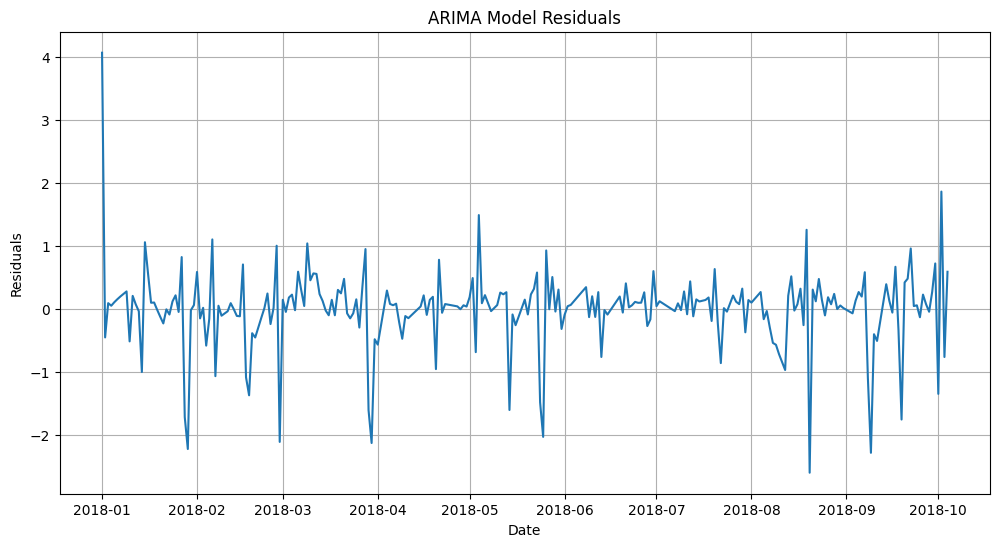

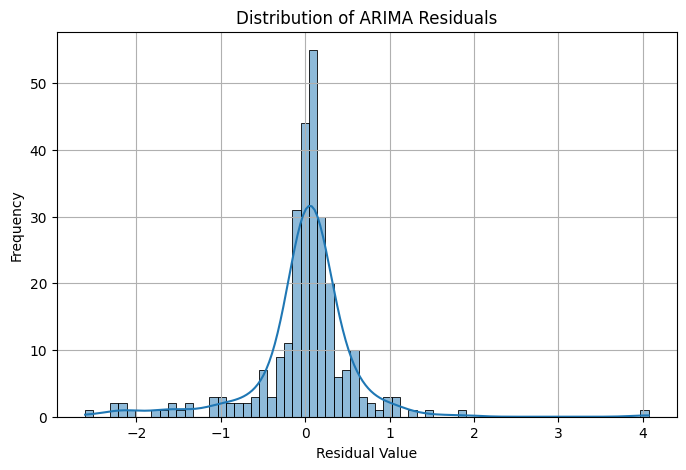

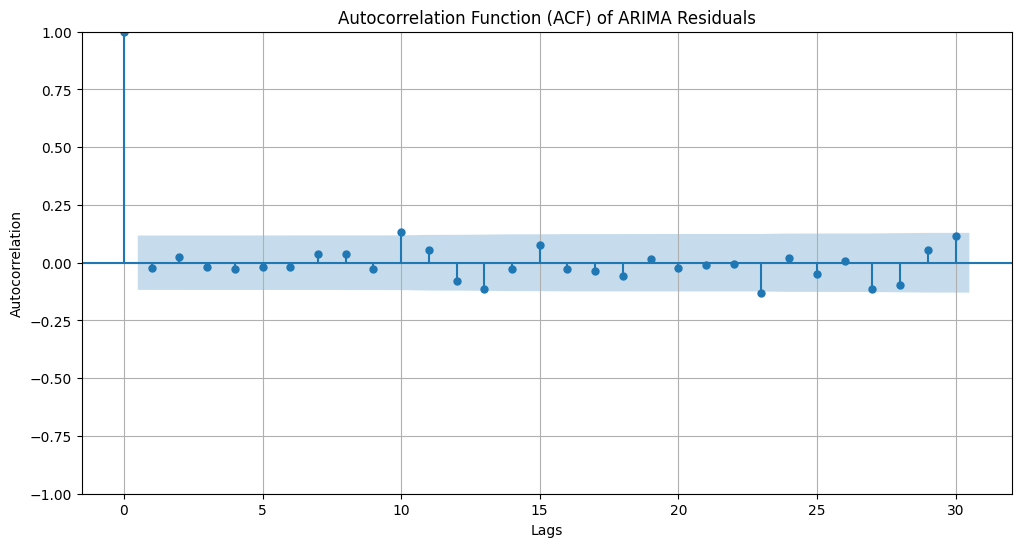

Ljung-Box test on Residuals:


,lb_stat,lb_pvalue
10,6.934652,0.7316


In [22]:
# Get the residuals
residuals = final_model_fit.resid

# Plot residuals
plt.figure(figsize=(12, 6))
plt.plot(residuals)
plt.title('ARIMA Model Residuals')
plt.xlabel('Date')
plt.ylabel('Residuals')
plt.grid(True)
plt.show()

# Plot distribution of residuals
plt.figure(figsize=(8, 5))
sns.histplot(residuals, kde=True)
plt.title('Distribution of ARIMA Residuals')
plt.xlabel('Residual Value')
plt.ylabel('Frequency')
plt.grid(True)
plt.show()

# Plot ACF of residuals to check for remaining autocorrelation
plt.figure(figsize=(12, 6))
plot_acf(residuals, lags=30, ax=plt.gca())
plt.title('Autocorrelation Function (ACF) of ARIMA Residuals')
plt.xlabel('Lags')
plt.ylabel('Autocorrelation')
plt.grid(True)
plt.show()

# Perform Ljung-Box test on residuals
print("Ljung-Box test on Residuals:")
# The Ljung-Box test checks for autocorrelations in the residuals.
# A small p-value suggests that the residuals are not white noise.
from statsmodels.stats.diagnostic import acorr_ljungbox
ljung_box_test = acorr_ljungbox(residuals, lags=[10], return_df=True) # Use a few lags, e.g., 10
ljung_box_test

In [23]:
# Model evaluation
predictions = model_fit.predict()
mae = np.mean(np.abs(residuals))
mse = np.mean(residuals ** 2)
rmse = np.sqrt(mse)
print(f"Mean Absolute Error (MAE): {mae}")
print(f"Mean Squared Error (MSE): {mse}")
print(f"Root Mean Squared Error (RMSE): {rmse}")

Mean Absolute Error (MAE): 0.35409812162697124
Mean Squared Error (MSE): 0.3795757705534492
Root Mean Squared Error (RMSE): 0.6160972086882469


**7. Forecasting Future Values**

Finally, we can use the fitted ARIMA model to make predictions for future values. Let’s forecast the next 30 days of returns and visualize the results.

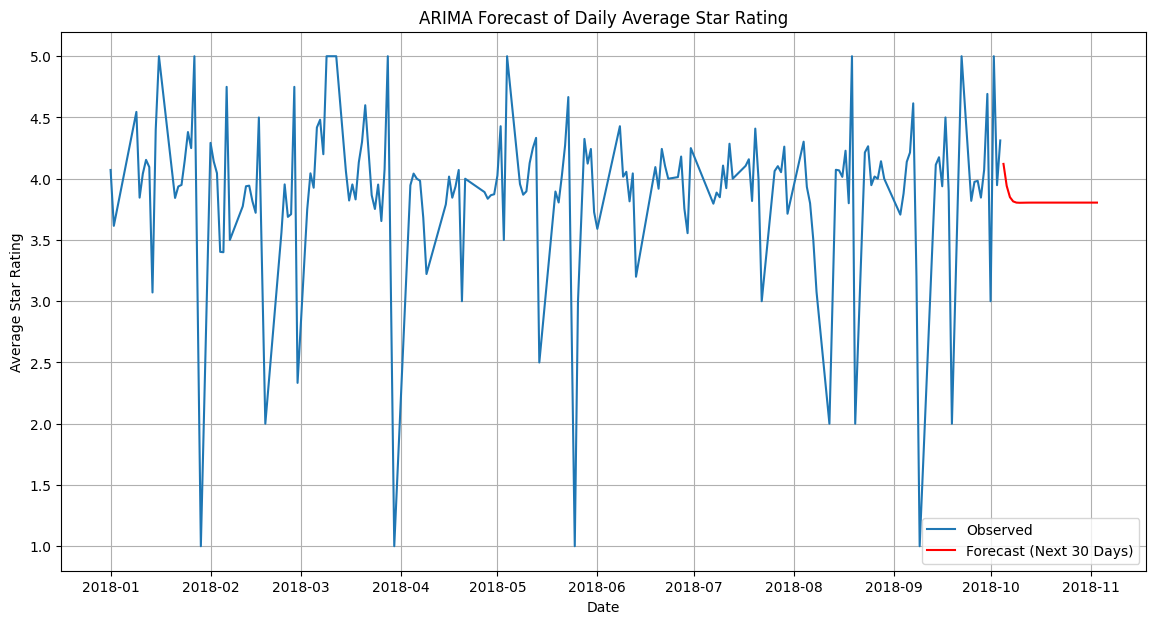

In [24]:
# Make predictions for the next 30 days
# Start forecasting from the end of the existing time series index
start_index = len(time_series)
end_index = start_index + 29  # Forecast for 30 days

# Get the forecast dates
forecast_dates = pd.date_range(start=time_series.index[-1] + pd.Timedelta(days=1), periods=30, freq='D')

# Use the final_model_fit (the best model found with d=1) to make predictions
# The predict method automatically handles the index for future dates
forecast = final_model_fit.predict(start=start_index, end=end_index)

# Assign the forecast dates to the predictions
forecast.index = forecast_dates

# Visualize the results
plt.figure(figsize=(14, 7))
plt.plot(time_series, label='Observed')
plt.plot(forecast, color='red', label='Forecast (Next 30 Days)')
plt.title('ARIMA Forecast of Daily Average Star Rating')
plt.xlabel('Date')
plt.ylabel('Average Star Rating')
plt.legend()
plt.grid(True)
plt.show()

we have explored the ARIMA model for time series forecasting in Python. We started by importing and preparing time series data, followed by exploratory data analysis and stationarity testing. We then analyzed autocorrelation and partial autocorrelation to determine the appropriate AR and MA components. After selecting the optimal model order, we estimated the parameters and evaluated the model’s performance. Finally, we made forecasts for future values and visualized the results.

Time series forecasting with ARIMA is a powerful technique for predicting future trends and patterns in sequential data. By understanding the underlying concepts and applying the ARIMA model, you can make accurate predictions and gain valuable insights from time series data.